In [2]:
!pip install -q pyspark==3.5.0 faker
!apt-get install -y openjdk-17-jdk-headless -qq > /dev/null
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

In [3]:
import random, json, csv, os
from faker import Faker
from datetime import datetime, timedelta

fake = Faker()
random.seed(42)
os.makedirs("data", exist_ok=True)

N_TX, N_FB, N_CUSTOMERS = 1_000_000, 250_000, 100_000
cities = ["Johannesburg","Cape Town","Durban","Pretoria","Port Elizabeth",
          "Bloemfontein","East London","Polokwane","Nelspruit","Kimberley"]
categories = ["Groceries","Electronics","Clothing","Home","Beauty","Sports","Toys"]
payment = ["Card","Cash","EFT","Mobile"]
start = datetime(2021, 1, 1)

with open("data/retailmart_transactions.csv","w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["transaction_id","customer_id","transaction_date","store_id",
                "city","product_category","quantity","unit_price",
                "total_amount","payment_method","loyalty_points"])
    for i in range(N_TX):
        cust = f"CU{random.randint(1,N_CUSTOMERS):06d}"
        dt = start + timedelta(days=random.randint(0, 365*5),
                               hours=random.randint(8,21),
                               minutes=random.randint(0,59))
        qty = random.randint(1,8)
        price = round(random.uniform(5, 800), 2)
        total = round(qty*price, 2)
        w.writerow([f"TX{i:08d}", cust, dt.isoformat(),
                    f"S{random.randint(1,500):03d}", random.choice(cities),
                    random.choice(categories), qty, price, total,
                    random.choice(payment), int(total//10)])
print("transactions written:", N_TX)

reviews = ["Great service!","Too expensive","Love the store","Will come back",
           "Poor quality","Excellent selection","Slow checkout","Friendly staff",
           "Out of stock","Amazing deals"]
with open("data/customer_feedback.json","w") as f:
    for i in range(N_FB):
        rec = {"feedback_id": f"FB{i:07d}",
               "customer_id": f"CU{random.randint(1,N_CUSTOMERS):06d}",
               "feedback_date": (start + timedelta(days=random.randint(0, 365*5))).isoformat(),
               "rating": random.choices([1,2,3,4,5],[5,10,20,35,30])[0],
               "review_text": random.choice(reviews),
               "store_id": f"S{random.randint(1,500):03d}"}
        f.write(json.dumps(rec)+"\n")
print("feedback written:", N_FB)

transactions written: 1000000
feedback written: 250000


In [4]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import *

spark = (SparkSession.builder
         .appName("RetailMart-CIP")
         .config("spark.sql.shuffle.partitions","8")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Spark 3.5.0


In [5]:
from pyspark.sql.functions import col, to_date, trim

tx = spark.read.csv("data/retailmart_transactions.csv", header=True, inferSchema=True)
fb = spark.read.json("data/customer_feedback.json")

print("Transactions:", tx.count(), "| Feedback:", fb.count())
tx.printSchema()
tx.show(5, truncate=False)

def profile(df, name):
    print(f"\n===== QUALITY PROFILE: {name} =====")
    n = df.count()
    print(f"Rows: {n:,}")
    for c in df.columns:
        nulls = df.filter(F.col(c).isNull()).count()
        distinct = df.select(c).distinct().count()
        print(f"  {c:20s} nulls={nulls:>8,} ({nulls/n:.2%})  distinct={distinct:,}")

profile(tx, "transactions")
profile(fb, "feedback")

Transactions: 1000000 | Feedback: 250000
root
 |-- transaction_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_date: timestamp (nullable = true)
 |-- store_id: string (nullable = true)
 |-- city: string (nullable = true)
 |-- product_category: string (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- unit_price: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- loyalty_points: integer (nullable = true)

+--------------+-----------+-------------------+--------+--------------+----------------+--------+----------+------------+--------------+--------------+
|transaction_id|customer_id|transaction_date   |store_id|city          |product_category|quantity|unit_price|total_amount|payment_method|loyalty_points|
+--------------+-----------+-------------------+--------+--------------+----------------+--------+----------+------------+--------------+--------------+
|TX0000000

In [6]:
tx_clean = (tx
    .dropDuplicates(["transaction_id"])
    .filter(col("quantity") > 0)
    .filter(col("unit_price") > 0)
    .withColumn("total_amount", F.round(col("quantity") * col("unit_price"), 2))
    .withColumn("transaction_date", to_date("transaction_date"))
    .withColumn("city", trim(col("city")))
)

fb_clean = (fb
    .dropDuplicates(["feedback_id"])
    .filter(col("rating").between(1,5))
    .withColumn("feedback_date", to_date("feedback_date"))
    .withColumn("review_text", trim(col("review_text")))
)

tx_clean.write.mode("overwrite").parquet("data/curated/transactions.parquet")
fb_clean.write.mode("overwrite").parquet("data/curated/feedback.parquet")
print("Clean rows:", tx_clean.count(), fb_clean.count())

Clean rows: 1000000 250000


In [7]:
snapshot = tx_clean.agg(F.max("transaction_date")).collect()[0][0]
print("Snapshot date:", snapshot)

rfm = (tx_clean.groupBy("customer_id").agg(
        F.datediff(F.lit(snapshot), F.max("transaction_date")).alias("recency"),
        F.count("transaction_id").alias("frequency"),
        F.round(F.sum("total_amount"),2).alias("monetary"),
        F.round(F.avg("total_amount"),2).alias("avg_basket"),
        F.countDistinct("product_category").alias("category_diversity"),
        F.sum("loyalty_points").alias("loyalty_points")
     )).fillna(0)

rfm.cache()
rfm.show(5)
rfm.write.mode("overwrite").parquet("data/curated/rfm.parquet")

Snapshot date: 2025-12-31
+-----------+-------+---------+--------+----------+------------------+--------------+
|customer_id|recency|frequency|monetary|avg_basket|category_diversity|loyalty_points|
+-----------+-------+---------+--------+----------+------------------+--------------+
|   CU051877|     94|        7| 8521.74|   1217.39|                 5|           848|
|   CU039111|    252|        8| 6258.86|    782.36|                 5|           622|
|   CU095016|     94|       12|21459.59|    1788.3|                 5|          2140|
|   CU096148|     10|       14| 23049.8|   1646.41|                 6|          2299|
|   CU084449|     80|       11|27187.49|   2471.59|                 6|          2710|
+-----------+-------+---------+--------+----------+------------------+--------------+
only showing top 5 rows



In [8]:
import os, time

def dir_size(path):
    return sum(os.path.getsize(os.path.join(dp,f))
               for dp,_,fs in os.walk(path) for f in fs)

for p in ["data/curated/transactions.parquet",
          "data/curated/feedback.parquet",
          "data/curated/rfm.parquet"]:
    print(f"{p:45s} {dir_size(p)/1e6:8.2f} MB")

tx_part = tx_clean.withColumn("year", F.year("transaction_date"))
tx_part.write.mode("overwrite").partitionBy("year")\
       .parquet("data/curated/transactions_by_year.parquet")

print("\nPartition folders:")
for d in sorted(os.listdir("data/curated/transactions_by_year.parquet")):
    if d.startswith("year="):
        print(" ", d)

t0 = time.time()
spark.read.parquet("data/curated/transactions_by_year.parquet")\
     .filter("year=2023").count()
print(f"Partitioned query: {time.time()-t0:.2f}s")

data/curated/transactions.parquet                25.99 MB
data/curated/feedback.parquet                     3.55 MB
data/curated/rfm.parquet                          2.08 MB

Partition folders:
  year=2021
  year=2022
  year=2023
  year=2024
  year=2025
Partitioned query: 0.61s


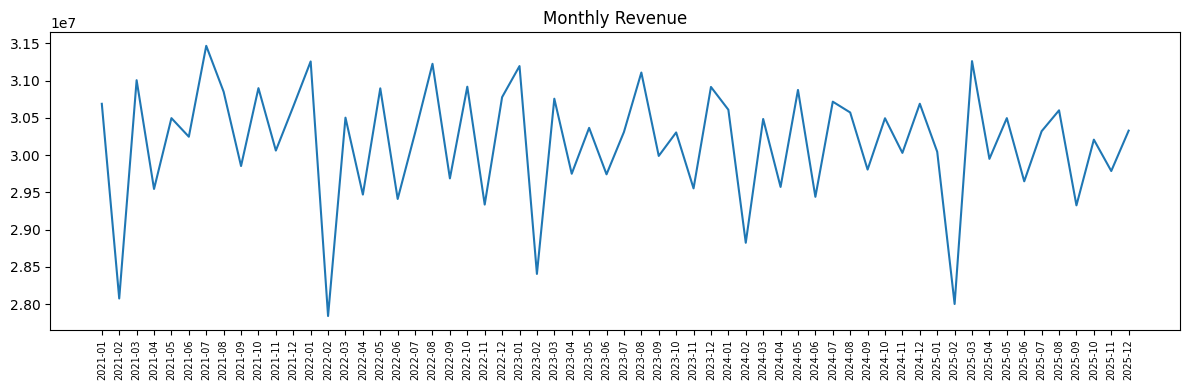

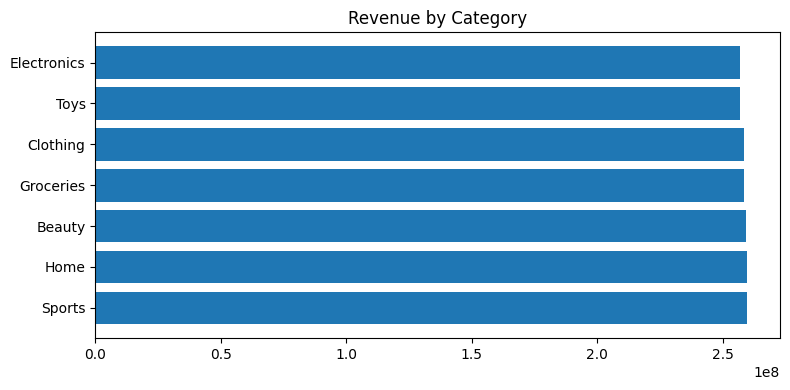

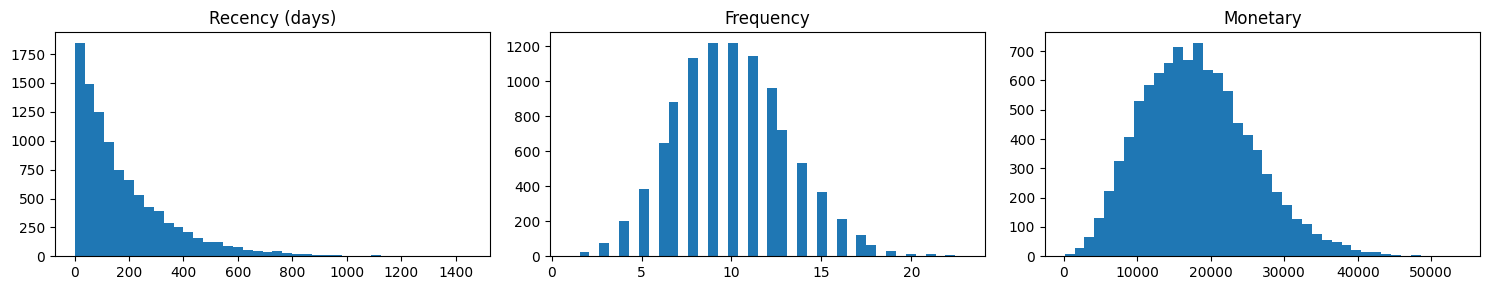

Tableau exports ready: data/tableau_export.csv, data/tableau_rfm.csv


In [9]:
import matplotlib.pyplot as plt
import pandas as pd

monthly = (tx_clean.withColumn("ym", F.date_format("transaction_date","yyyy-MM"))
           .groupBy("ym").agg(F.sum("total_amount").alias("revenue"))
           .orderBy("ym").toPandas())
plt.figure(figsize=(12,4))
plt.plot(monthly["ym"], monthly["revenue"])
plt.xticks(rotation=90, fontsize=7)
plt.title("Monthly Revenue"); plt.tight_layout(); plt.show()

cat = (tx_clean.groupBy("product_category")
       .agg(F.sum("total_amount").alias("rev"))
       .orderBy(F.desc("rev")).toPandas())
plt.figure(figsize=(8,4))
plt.barh(cat["product_category"], cat["rev"])
plt.title("Revenue by Category"); plt.tight_layout(); plt.show()

rfm_pd = rfm.sample(0.1, seed=1).toPandas()
fig, ax = plt.subplots(1,3, figsize=(15,3))
ax[0].hist(rfm_pd["recency"], bins=40);   ax[0].set_title("Recency (days)")
ax[1].hist(rfm_pd["frequency"], bins=40); ax[1].set_title("Frequency")
ax[2].hist(rfm_pd["monetary"], bins=40);  ax[2].set_title("Monetary")
plt.tight_layout(); plt.show()

export = (tx_clean.groupBy("city","product_category","payment_method")
          .agg(F.count("*").alias("n_tx"),
               F.sum("total_amount").alias("revenue"),
               F.avg("total_amount").alias("avg_ticket")))
export.toPandas().to_csv("data/tableau_export.csv", index=False)
rfm.toPandas().to_csv("data/tableau_rfm.csv", index=False)
print("Tableau exports ready: data/tableau_export.csv, data/tableau_rfm.csv")

In [10]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import (BinaryClassificationEvaluator,
                                   MulticlassClassificationEvaluator)

rfm_churn = rfm.withColumn("churn", (F.col("recency") > 180).cast("int"))
print(rfm_churn.groupBy("churn").count().show())

features = ["frequency","monetary","avg_basket",
            "category_diversity","loyalty_points"]
asm = VectorAssembler(inputCols=features, outputCol="features")
data = asm.transform(rfm_churn).select("features","churn","customer_id")
train, test = data.randomSplit([0.8,0.2], seed=42)

dt = DecisionTreeClassifier(labelCol="churn", featuresCol="features",
                            maxDepth=6, seed=42)
dt_model = dt.fit(train)
pred = dt_model.transform(test)

auc = BinaryClassificationEvaluator(labelCol="churn",
        metricName="areaUnderROC").evaluate(pred)
acc = MulticlassClassificationEvaluator(labelCol="churn",
        metricName="accuracy").evaluate(pred)
f1  = MulticlassClassificationEvaluator(labelCol="churn",
        metricName="f1").evaluate(pred)
print(f"AUC={auc:.3f}  Acc={acc:.3f}  F1={f1:.3f}")

print("\nFeature importance:")
for f, imp in zip(features, dt_model.featureImportances.toArray()):
    print(f"  {f:22s} {imp:.3f}")

+-----+-----+
|churn|count|
+-----+-----+
|    1|37320|
|    0|62677|
+-----+-----+

None
AUC=0.460  Acc=0.650  F1=0.590

Feature importance:
  frequency              0.992
  monetary               0.003
  avg_basket             0.003
  category_diversity     0.002
  loyalty_points         0.001


In [11]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.feature import StandardScaler

seg_feats = ["recency","frequency","monetary"]
asm2 = VectorAssembler(inputCols=seg_feats, outputCol="raw")
scaler = StandardScaler(inputCol="raw", outputCol="features",
                        withMean=True, withStd=True)
scaled = scaler.fit(asm2.transform(rfm)).transform(asm2.transform(rfm))

kmeans = KMeans(k=4, seed=42, featuresCol="features")
km_model = kmeans.fit(scaled)
segmented = (km_model.transform(scaled)
             .select("customer_id","prediction","recency","frequency","monetary"))

print("\nSegment profiles:")
(segmented.groupBy("prediction").agg(
    F.round(F.avg("recency"),0).alias("avg_recency"),
    F.round(F.avg("frequency"),1).alias("avg_freq"),
    F.round(F.avg("monetary"),0).alias("avg_monetary"),
    F.count("*").alias("n"))
 .orderBy("prediction").show())


Segment profiles:
+----------+-----------+--------+------------+-----+
|prediction|avg_recency|avg_freq|avg_monetary|    n|
+----------+-----------+--------+------------+-----+
|         0|      552.0|     7.4|     12929.0|12813|
|         1|      129.0|    10.9|     19860.0|39336|
|         2|      114.0|    14.5|     29235.0|17117|
|         3|      137.0|     7.4|     11799.0|30731|
+----------+-----------+--------+------------+-----+



Explained variance: [0.66766249 0.24647996]


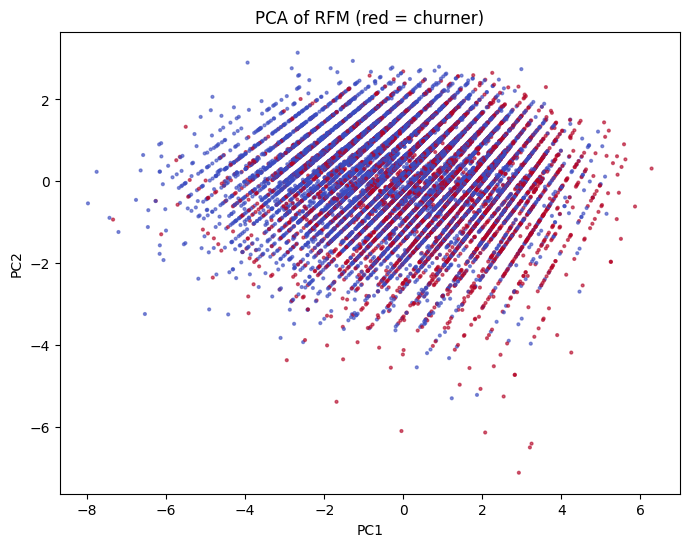

In [12]:
from pyspark.ml.feature import PCA
import numpy as np, matplotlib.pyplot as plt

asm3 = VectorAssembler(inputCols=features, outputCol="f")
scaler3 = StandardScaler(inputCol="f", outputCol="features",
                         withMean=True, withStd=True)
scaled3 = scaler3.fit(asm3.transform(rfm_churn)).transform(asm3.transform(rfm_churn))

pca = PCA(k=2, inputCol="features", outputCol="pca").fit(scaled3)
pca_df = pca.transform(scaled3).select("customer_id","churn","pca")
print("Explained variance:", pca.explainedVariance.toArray())

pdf = pca_df.sample(0.15, seed=1).toPandas()
xs = np.array([v[0] for v in pdf["pca"]])
ys = np.array([v[1] for v in pdf["pca"]])
plt.figure(figsize=(8,6))
plt.scatter(xs, ys, c=pdf["churn"], cmap="coolwarm", s=4, alpha=0.6)
plt.title("PCA of RFM (red = churner)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

In [13]:
import json

dt_model.write().overwrite().save("data/models/churn_dt")
km_model.write().overwrite().save("data/models/segment_km")

with open("data/scoring_meta.json","w") as f:
    json.dump({"model":"DecisionTreeClassifier",
               "features":features,
               "churn_threshold_days":180,
               "segments":4,
               "tableau_exports":["data/tableau_export.csv",
                                  "data/tableau_rfm.csv"]}, f, indent=2)

def score_customer(recency, frequency, monetary,
                   avg_basket, category_diversity, loyalty_points):
    """Simulated online scoring endpoint."""
    row = spark.createDataFrame([(frequency, monetary, avg_basket,
                                  category_diversity, loyalty_points)],
                                ["frequency","monetary","avg_basket",
                                 "category_diversity","loyalty_points"])
    pred = dt_model.transform(asm.transform(row)).first()["prediction"]
    return "WILL_CHURN" if pred == 1.0 else "RETAINED"

print("Sample score:", score_customer(240, 1, 55.0, 55.0, 1, 5))
print("Sample score:", score_customer(10, 40, 900.0, 200.0, 6, 850))

Sample score: WILL_CHURN
Sample score: WILL_CHURN


In [14]:
from google.colab import files
for p in ["data/tableau_export.csv",
          "data/tableau_rfm.csv",
          "data/model_comparison.csv",
          "data/scoring_meta.json"]:
    try:
        files.download(p)
    except Exception as e:
        print("skip", p, e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

skip data/model_comparison.csv Cannot find file: data/model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>